# Experimento 10 — Configurações fixas e validação por similaridade

200 candidatos por categoria, cada um com família e hiperparâmetros fixos nos três
anos mais semelhantes a 2026. Selecionamos os três menores scores ponderados de M e W
separadamente. Top1/2/3 agora identifica configurações do ranking global da categoria,
não posições de AutoMLs independentes por ano.

Mantemos as 14 features, a preparação e os estimadores H2O do projeto. A busca passa
a ser aleatória e reproduzível em espaços explícitos. Não há busca AutoML por ano;
ensembles automáticos ficam fora porque dependeriam de conjuntos de modelos diferentes.


## Configuração e custo

200 configurações × 3 anos × 2 categorias = **1.200 treinos principais**, mais seis finais.
Mantemos cinco folds internos por Season para diagnóstico de RMSE; isso acrescenta até
6.000 ajustes de CV na validação. RMSE interna não seleciona candidatos.
Não há limite de tempo. O treinamento completo pode ser bastante demorado.

Os candidatos são definidos sem consultar resultados: por categoria, 20 GLM, 90 GBM,
50 Random Forest e 40 Extra Trees (DRF com histogramas Random). DeepLearning e
XGBoost continuam fora. Configurações duplicadas não são contadas como novos candidatos.


In [27]:
from pathlib import Path
import sys
import json
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display

pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "raw_data").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Pasta raw_data não encontrada.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.data_processing import carregar_dados, preparar_seeds, organizar_jogos
from src.features import (
    adicionar_seeds, calcular_estatisticas_agregadas, adicionar_estatisticas,
    ESTATISTICAS_DETALHADAS, calcular_estatisticas_detalhadas, adicionar_estatisticas_detalhadas,
)
from src.automl_h2o import inicializar_h2o, limpar_execucao, AdaptadorH2O
from src.submission import preparar_confrontos, prever_confrontos, salvar_submission
from src.metrics import logistic_brier
import importlib
import src.h2o_candidates as modulo_candidatos
importlib.reload(modulo_candidatos)
from src.h2o_candidates import (
    espacos_candidatos, gerar_candidatos_h2o, avaliar_candidatos_h2o,
    ranquear_candidatos, treinar_candidato_h2o, backtest_candidatos,
)
from src.season_similarity import (
    VARIAVEIS_PERFIL, DIMENSOES_PERFIL, construir_perfis_temporadas,
    ranquear_temporadas, ponderar_temporadas,
)

EXPERIMENTO = "exp10_candidatos_fixos_ponderados"
FEATURES_EXP4 = ["SeedDif", "WinRateDiff", "AvgPointsForDiff", "AvgPointsAgainstDiff", "OppWinRateDiff"]
FEATURES = [*FEATURES_EXP4, *[nome + "Diff" for nome in ESTATISTICAS_DETALHADAS]]
INICIO_DETALHADO = {"M": 2003, "W": 2010}
ANOS_VALIDACAO = list(range(2021, 2026))
TEMPORADA_PREVISAO = 2026
LIMITE_DAYNUM_PREVISAO = 134
CATEGORIAS = {"M": "Masculino", "W": "Feminino"}
SEED = 42
N_CANDIDATOS = 200
N_REFERENCIAS = 3
TOP_N = 3
N_FOLDS_INTERNOS = 5
N_THREADS = 2
MAX_MEM_SIZE = "4G"
METRICA_PRINCIPAL = "euclidiana"
EXECUTAR_BACKTEST = False
ANOS_BACKTEST = [2022, 2023, 2024, 2025]
assert len(FEATURES) == 14 and "EloDiff" not in FEATURES


## Dados e features

Mesmos recortes pré-NCAA do Exp. 8: M desde 2003, W desde 2010, e DayNum < 134
para 2026. Target continua ScoreA − ScoreB, com TeamA menor que TeamB.


In [28]:
dados = {
    categoria: carregar_dados(raiz / "raw_data", categoria, incluir_regular=True, incluir_detalhado=True)
    for categoria in CATEGORIAS
}
assert set(dados["M"]["times"]["TeamID"]).isdisjoint(set(dados["W"]["times"]["TeamID"]))
seeds, estatisticas, detalhadas, jogos, limites, coberturas = {}, {}, {}, {}, {}, []
chaves_jogo = ["Season", "DayNum", "WTeamID", "LTeamID"]
for categoria, base in dados.items():
    torneios = base["resultados"].loc[base["resultados"]["Season"] < TEMPORADA_PREVISAO].copy()
    limites[categoria] = torneios.groupby("Season")["DayNum"].min().to_dict()
    limites[categoria][TEMPORADA_PREVISAO] = LIMITE_DAYNUM_PREVISAO
    raw_detalhes = base["temporada_regular_detalhada"]
    assert raw_detalhes["Season"].min() == INICIO_DETALHADO[categoria]
    anos = set(raw_detalhes["Season"]) & set(limites[categoria])
    assert set([*ANOS_VALIDACAO, TEMPORADA_PREVISAO]).issubset(anos)
    regulares = base["temporada_regular"].loc[base["temporada_regular"]["Season"].isin(anos)].copy()
    detalhes = raw_detalhes.loc[raw_detalhes["Season"].isin(anos)].copy()
    ids = set(base["times"]["TeamID"])
    for tabela in [regulares, detalhes]:
        assert (tabela["DayNum"] < tabela["Season"].map(limites[categoria])).all()
        assert tabela.merge(torneios[chaves_jogo], on=chaves_jogo).empty
        assert tabela["WTeamID"].isin(ids).all() and tabela["LTeamID"].isin(ids).all()
    conferidos = detalhes.merge(regulares[chaves_jogo + ["WScore", "LScore"]],
        on=chaves_jogo, how="left", suffixes=("", "Compact"), validate="one_to_one", indicator=True)
    assert conferidos["_merge"].eq("both").all()
    for placar in ["WScore", "LScore"]:
        np.testing.assert_array_equal(conferidos[placar], conferidos[placar + "Compact"])

    cobertura = regulares.groupby("Season").size().rename("JogosCompact").to_frame()
    cobertura["JogosDetalhados"] = detalhes.groupby("Season").size()
    cobertura["SemDetalhes"] = cobertura["JogosCompact"] - cobertura["JogosDetalhados"]
    cobertura["Cobertura"] = cobertura["JogosDetalhados"] / cobertura["JogosCompact"]
    cobertura["UltimoDayNumDetalhado"] = detalhes.groupby("Season")["DayNum"].max()
    cobertura["LimiteExclusivo"] = cobertura.index.map(limites[categoria])
    coberturas.append(cobertura.reset_index().assign(Categoria=categoria))
    seeds[categoria] = preparar_seeds(base["seeds"])
    estatisticas[categoria] = calcular_estatisticas_agregadas(regulares, limites_daynum=limites[categoria])
    detalhadas[categoria] = calcular_estatisticas_detalhadas(detalhes, limites_daynum=limites[categoria])
    historico = torneios.loc[torneios["Season"].isin(anos)]
    tabela = adicionar_seeds(organizar_jogos(historico), seeds[categoria])
    tabela = adicionar_estatisticas(tabela, estatisticas[categoria])
    tabela = adicionar_estatisticas_detalhadas(tabela, detalhadas[categoria])
    assert len(tabela) == len(historico)
    assert (tabela["TeamA"] < tabela["TeamB"]).all()
    assert tabela["Target"].equals(tabela["ScoreA"] - tabela["ScoreB"])
    assert tabela["SeedDif"].equals(tabela["SeedA"] - tabela["SeedB"])
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    for stats, nomes in [(estatisticas[categoria], ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]),
                          (detalhadas[categoria], ESTATISTICAS_DETALHADAS)]:
        lookup = stats.set_index(["Season", "TeamID"])
        for nome in nomes:
            a = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamA"]])).to_numpy()
            b = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamB"]])).to_numpy()
            np.testing.assert_allclose(tabela[nome + "Diff"], a - b)
    jogos[categoria] = tabela

cobertura = pd.concat(coberturas, ignore_index=True)
display(cobertura)

divisoes = pd.DataFrame([
    {"Categoria": categoria, "AnoValidacao": ano,
     "PrimeiroAnoTreino": tabela.loc[tabela.Season < ano, "Season"].min(),
     "UltimoAnoTreino": tabela.loc[tabela.Season < ano, "Season"].max(),
     "JogosTreino": int(tabela.Season.lt(ano).sum()), "JogosValidacao": int(tabela.Season.eq(ano).sum())}
    for categoria, tabela in jogos.items() for ano in ANOS_VALIDACAO
])
assert (divisoes.UltimoAnoTreino < divisoes.AnoValidacao).all()
assert divisoes.JogosValidacao.gt(0).all()
assert divisoes.loc[divisoes.AnoValidacao.eq(2021), "UltimoAnoTreino"].eq(2019).all()
for categoria, tabela in jogos.items():
    assert tabela.Season.max() == 2025
    assert tabela.Season.min() == INICIO_DETALHADO[categoria]
    assert np.isfinite(tabela[[*FEATURES, "Target"]].to_numpy()).all()
display(divisoes)


,Season,JogosCompact,JogosDetalhados,SemDetalhes,Cobertura,UltimoDayNumDetalhado,LimiteExclusivo,Categoria
0,2003,4616,4616,0,1.000000,132,134,M
1,2004,4571,4571,0,1.000000,132,134,M
2,2005,4675,4675,0,1.000000,132,134,M
3,2006,4757,4757,0,1.000000,132,134,M
4,2007,5043,5043,0,1.000000,132,134,M
5,2008,5163,5163,0,1.000000,132,134,M
6,2009,5249,5249,0,1.000000,132,134,M
7,2010,5263,5263,0,1.000000,132,134,M
8,2011,5246,5246,0,1.000000,132,134,M
9,2012,5253,5253,0,1.000000,132,134,M


,Categoria,AnoValidacao,PrimeiroAnoTreino,UltimoAnoTreino,JogosTreino,JogosValidacao
0,M,2021,2003,2019,1115,66
1,M,2022,2003,2021,1181,67
2,M,2023,2003,2022,1248,67
3,M,2024,2003,2023,1315,67
4,M,2025,2003,2024,1382,67
5,W,2021,2010,2019,630,63
6,W,2022,2010,2021,693,67
7,W,2023,2010,2022,760,67
8,W,2024,2010,2023,827,67
9,W,2025,2010,2024,894,67


## Perfis e similaridade

Média e desvio populacional das 13 estatísticas de equipe, apenas para participantes.
M/W são agregados separadamente e concatenados. Seed não entra na distância.
O scaler usa apenas perfis anteriores ao ano alvo; não utiliza Target ou score Kaggle.


In [29]:
perfis_resultado = construir_perfis_temporadas(
    dados, limites, inicio=INICIO_DETALHADO, ano_maximo=TEMPORADA_PREVISAO,
)
perfis = perfis_resultado["perfis"]
assert len(DIMENSOES_PERFIL) == 52
assert perfis.Season.is_unique and np.isfinite(perfis.to_numpy()).all()
assert perfis.Season.min() == 2010 and perfis.Season.max() == 2026
assert not {"Target", "Pred", "Seed"} & set(perfis.columns)
display(perfis_resultado["contagens"].pivot(index="Season", columns="Categoria", values="Participantes"))
display(perfis)


Categoria,M,W
Season,,
2003,65.0,NaN
2004,65.0,NaN
2005,65.0,NaN
2006,65.0,NaN
2007,65.0,NaN
2008,65.0,NaN
2009,65.0,NaN
2010,65.0,64.0
2011,68.0,64.0


,Season,M_WinRate_mean,M_WinRate_std,M_AvgPointsFor_mean,M_AvgPointsFor_std,M_AvgPointsAgainst_mean,M_AvgPointsAgainst_std,M_OppWinRate_mean,M_OppWinRate_std,M_FGPercentage_mean,...,W_OffensiveReboundsPerGame_mean,W_OffensiveReboundsPerGame_std,W_DefensiveReboundsPerGame_mean,W_DefensiveReboundsPerGame_std,W_TurnoversPerGame_mean,W_TurnoversPerGame_std,W_StealsPerGame_mean,W_StealsPerGame_std,W_BlocksPerGame_mean,W_BlocksPerGame_std
0,2010,0.742672,0.091255,74.005013,4.799320,65.461678,4.372909,0.532298,0.052845,0.457352,...,13.895711,1.657054,25.687913,2.219846,16.452419,1.743380,9.140089,1.860896,3.851896,1.218143
1,2011,0.715472,0.107354,72.066243,5.053833,64.612180,3.578404,0.538740,0.055783,0.450573,...,13.612505,2.286526,25.601799,2.184419,16.084889,1.601641,9.118763,1.984974,3.641349,1.149270
2,2012,0.740735,0.089771,72.547485,4.890485,64.203399,4.352902,0.532190,0.051310,0.456690,...,13.985352,2.450664,25.585194,2.072826,15.720095,1.621929,9.146569,1.878964,3.820412,1.202799
3,2013,0.728853,0.092690,71.472411,4.288672,63.475566,4.416142,0.535201,0.052903,0.452557,...,13.871742,2.172821,26.051162,1.849953,15.332262,1.767001,9.264444,1.806681,3.865471,1.022040
4,2014,0.723180,0.107434,74.148031,4.750103,66.673688,5.041113,0.534139,0.055341,0.457552,...,13.531667,2.128654,27.022466,2.101656,14.974151,1.796546,8.160934,1.721740,3.814367,1.311842
5,2015,0.723572,0.105118,71.286885,4.740511,63.659785,5.063409,0.530196,0.054726,0.454935,...,13.437143,2.138766,26.623299,2.218039,14.769429,1.717700,8.517734,1.650261,4.173639,1.326452
6,2016,0.709913,0.093366,75.854569,3.810028,68.440009,4.097866,0.531094,0.054151,0.456633,...,13.458345,1.970282,26.659743,2.122224,15.236592,1.829616,8.295960,1.648272,4.084539,1.181892
7,2017,0.732512,0.102090,76.619748,4.840920,68.358113,4.871807,0.529714,0.056551,0.465174,...,13.310902,1.801972,26.274813,2.688777,14.310973,1.856204,8.157366,1.937273,3.987251,1.189350
8,2018,0.714144,0.099058,77.763324,4.751097,70.113137,5.047647,0.528330,0.057417,0.465919,...,12.809611,1.844721,26.764417,2.383576,14.053305,1.970483,7.995952,1.946964,3.874187,1.045222
9,2019,0.730204,0.105218,75.113093,4.973926,67.298818,4.479640,0.527203,0.057687,0.459023,...,12.581020,1.867534,26.423528,2.440537,14.224351,1.856284,8.004299,1.703216,3.717287,1.138663


## Três anos de validação e pesos

Distância Euclidiana principal. Os três anos mais próximos recebem pesos
`w_t = (1/d_t) / soma(1/d)`. Se houver distância zero, seu peso é dividido entre os
empates de distância zero. Pesos são fixados antes de consultar o desempenho dos candidatos.

Em cada ano T, treino = Season < T e validação = Season == T. O mesmo candidato é
treinado novamente em cada recorte; nunca usamos um modelo treinado até 2025 para avaliar 2023.


,Dimensao,MediaHistorica,DesvioHistorico,EscalaUsada
0,M_WinRate_mean,0.723001,0.010319,0.010319
1,M_WinRate_std,0.098814,0.006025,0.006025
2,M_AvgPointsFor_mean,74.591195,2.062284,2.062284
3,M_AvgPointsFor_std,4.702178,0.397449,0.397449
4,M_AvgPointsAgainst_mean,66.830807,2.106159,2.106159
5,M_AvgPointsAgainst_std,4.400017,0.450100,0.450100
6,M_OppWinRate_mean,0.529918,0.005319,0.005319
7,M_OppWinRate_std,0.054440,0.002686,0.002686
8,M_FGPercentage_mean,0.458217,0.004199,0.004199
9,M_FGPercentage_std,0.021864,0.001513,0.001513


,Season,Distancia,Ranking
0,2025,7.624698,1
1,2024,8.193139,2
2,2023,10.326554,3
3,2022,12.008314,4
4,2021,13.489257,5


Três referências mais próximas: [2025, 2024, 2023]
Ano mais próximo (diagnóstico): 2025; distância: 7.624698


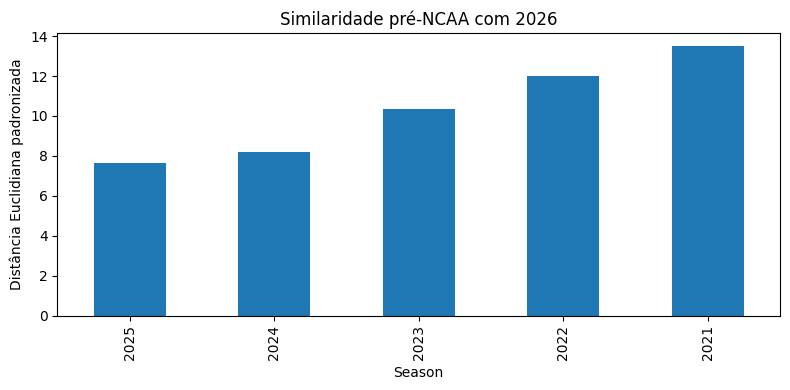

,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


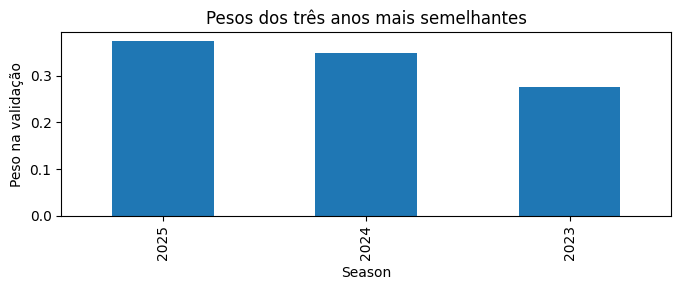

In [30]:
similaridade_2026 = ranquear_temporadas(
    perfis, TEMPORADA_PREVISAO, ANOS_VALIDACAO, metrica=METRICA_PRINCIPAL,
)
ranking_2026 = similaridade_2026["ranking"]
ANO_REFERENCIA_2026 = int(ranking_2026.iloc[0].Season)
DISTANCIA_2026 = float(ranking_2026.iloc[0].Distancia)
assert max(similaridade_2026["anos_padronizacao"]) < TEMPORADA_PREVISAO
display(similaridade_2026["normalizacao"])
display(ranking_2026)
print("Três referências mais próximas:", ranking_2026.head(3).Season.tolist())
print(f"Ano mais próximo (diagnóstico): {ANO_REFERENCIA_2026}; distância: {DISTANCIA_2026:.6f}")

import matplotlib.pyplot as plt
ax = ranking_2026.set_index("Season").Distancia.plot.bar(
    figsize=(8, 4), ylabel="Distância Euclidiana padronizada", title="Similaridade pré-NCAA com 2026")
plt.tight_layout()
plt.show()

REFERENCIAS_2026 = ponderar_temporadas(ranking_2026, n_referencias=N_REFERENCIAS)
assert len(REFERENCIAS_2026) == N_REFERENCIAS
assert REFERENCIAS_2026.Season.lt(TEMPORADA_PREVISAO).all()
np.testing.assert_allclose(REFERENCIAS_2026.Peso.sum(), 1.)
display(REFERENCIAS_2026)
ax = REFERENCIAS_2026.set_index("Season").Peso.plot.bar(
    figsize=(7, 3), ylabel="Peso na validação", title="Pesos dos três anos mais semelhantes")
plt.tight_layout()
plt.show()


## Contribuições e sensibilidade

Mostramos contribuições do ano mais próximo e comparamos com Manhattan.
Euclidiana permanece a regra principal independentemente do resultado da sensibilidade.


In [31]:
contribuicoes = similaridade_2026["contribuicoes"]
contribuicoes_referencia = contribuicoes.loc[contribuicoes.Season.eq(ANO_REFERENCIA_2026)].sort_values(
    "Contribuicao", ascending=False)
display(contribuicoes_referencia.head(12))
display(contribuicoes_referencia.tail(8).sort_values("Contribuicao"))
por_variavel = contribuicoes_referencia.copy()
por_variavel["Variavel"] = por_variavel.Dimensao.str[2:].str.rsplit("_", n=1).str[0]
display(por_variavel.groupby("Variavel")[["Contribuicao", "Fracao"]].sum().sort_values("Contribuicao", ascending=False))
np.testing.assert_allclose(contribuicoes_referencia.Contribuicao.sum(), DISTANCIA_2026 ** 2)

sensibilidade = ranquear_temporadas(perfis, TEMPORADA_PREVISAO, ANOS_VALIDACAO, metrica="manhattan")
display(ranking_2026.merge(sensibilidade["ranking"], on="Season", suffixes=("Euclidiana", "Manhattan")))
ANO_MANHATTAN = int(sensibilidade["ranking"].iloc[0].Season)
print("Referência estável entre métricas." if ANO_MANHATTAN == ANO_REFERENCIA_2026
      else f"Divergência: Euclidiana={ANO_REFERENCIA_2026}, Manhattan={ANO_MANHATTAN}. Mantemos Euclidiana.")

display(ponderar_temporadas(sensibilidade["ranking"], n_referencias=N_REFERENCIAS).rename(columns={"Peso": "PesoManhattan"}))


,Season,Dimensao,Contribuicao,Fracao
79,2025,M_AssistsPerGame_std,9.725254,0.167284
39,2025,M_OppWinRate_std,5.990222,0.103038
134,2025,W_WinRate_mean,3.225029,0.055474
179,2025,W_FGPercentage_std,3.096788,0.053268
69,2025,M_FTPercentage_std,2.521581,0.043374
89,2025,M_OffensiveReboundsPerGame_std,2.269234,0.039033
34,2025,M_OppWinRate_mean,1.994573,0.034309
249,2025,W_StealsPerGame_std,1.986000,0.034161
14,2025,M_AvgPointsFor_mean,1.841208,0.031671
184,2025,W_ThreePointPercentage_mean,1.826785,0.031423


,Season,Dimensao,Contribuicao,Fracao
119,2025,M_StealsPerGame_std,0.003921,0.000067
64,2025,M_FTPercentage_mean,0.005923,0.000102
234,2025,W_TurnoversPerGame_mean,0.009279,0.000160
124,2025,M_BlocksPerGame_mean,0.010217,0.000176
94,2025,M_DefensiveReboundsPerGame_mean,0.014549,0.000250
204,2025,W_AssistsPerGame_mean,0.018547,0.000319
214,2025,W_OffensiveReboundsPerGame_mean,0.020570,0.000354
229,2025,W_DefensiveReboundsPerGame_std,0.025157,0.000433


,Contribuicao,Fracao
Variavel,,
AssistsPerGame,12.249974,0.210712
OppWinRate,8.597453,0.147885
FGPercentage,6.160330,0.105964
WinRate,4.829794,0.083077
ThreePointPercentage,4.337744,0.074614
AvgPointsFor,4.107729,0.070657
FTPercentage,3.938688,0.067750
AvgPointsAgainst,3.214771,0.055297
TurnoversPerGame,2.829846,0.048676


,Season,DistanciaEuclidiana,RankingEuclidiana,DistanciaManhattan,RankingManhattan
0,2025,7.624698,1,44.050373,2
1,2024,8.193139,2,43.930916,1
2,2023,10.326554,3,57.333175,3
3,2022,12.008314,4,72.780775,4
4,2021,13.489257,5,77.108703,5


Divergência: Euclidiana=2025, Manhattan=2024. Mantemos Euclidiana.


,Season,Distancia,PesoManhattan
0,2024,43.930916,0.361856
1,2025,44.050373,0.360875
2,2023,57.333175,0.277268


## Banco fixo de candidatos

Cada ID representa família + parâmetros + seed. GLM usa alpha/lambda fixos, sem
lambda search. Árvores usam ntrees fixo e stopping_rounds=0, para não trocar o orçamento
do candidato com o ano. Os pesos/coefficientes do modelo são reaprendidos em cada treino.

O banco é gerado sem scores ou dados de torneio e permanece igual até o treino final.
A amostragem e os parâmetros estão registrados abaixo. Não misturamos modelos M/W.


In [32]:
ESPACOS = espacos_candidatos(len(FEATURES))
candidatos = {
    categoria: gerar_candidatos_h2o(categoria=categoria, n_candidatos=N_CANDIDATOS,
        seed=SEED, n_features=len(FEATURES)) for categoria in CATEGORIAS
}
catalogo = pd.DataFrame([c for banco in candidatos.values() for c in banco])
assert catalogo.Candidato.is_unique
assert catalogo.groupby("Categoria").size().eq(N_CANDIDATOS).all()
display(catalogo.groupby(["Categoria", "Familia"]).size().rename("Configurações").unstack(fill_value=0))
display(ESPACOS)
ANOS_TREINAR = ANOS_VALIDACAO if EXECUTAR_BACKTEST else sorted(REFERENCIAS_2026.Season.astype(int).tolist())
print("Anos de validação efetivamente treinados:", ANOS_TREINAR)
print("Treinos principais:", N_CANDIDATOS * 2 * len(ANOS_TREINAR))


Familia,GBM,GLM,RF,XRT
Categoria,,,,
M,90,20,50,40
W,90,20,50,40


{'GLM': {'alpha': [0.0, 0.1, 0.25, 0.5, 0.75, 1.0],
  'lambda_': [0.0,
   1e-06,
   1.3990503141372929e-06,
   1.9573417814876616e-06,
   2.7384196342643613e-06,
   3.831186849557285e-06,
   5.3600231653917955e-06,
   7.498942093324558e-06,
   1.0491397291363112e-05,
   1.4677992676220705e-05,
   2.0535250264571462e-05,
   2.8729848333536687e-05,
   4.019450333615128e-05,
   5.623413251903491e-05,
   7.86743807659941e-05,
   0.00011006941712522103,
   0.0001539926526059492,
   0.00021544346900318845,
   0.0003014162529877392,
   0.00042169650342858224,
   0.0005899746255923565,
   0.000825404185268019,
   0.0011547819846894581,
   0.0016155980984398745,
   0.0022603030271419215,
   0.0031622776601683794,
   0.004424185553847919,
   0.00618965818891261,
   0.008659643233600663,
   0.012115276586285901,
   0.01694988151390348,
   0.023713737056616554,
   0.03317671127842862,
   0.04641588833612782,
   0.06493816315762113,
   0.0908517575651688,
   0.12710617996147458,
   0.17782794100389

Anos de validação efetivamente treinados: [2023, 2024, 2025]
Treinos principais: 1200


## Avaliação das configurações fixas

Treinamos todos os candidatos nos anos definidos acima. As cinco divisões internas
por Season usam apenas o histórico de treino. O ano externo nunca é enviado ao estimador.
Modelos temporários são removidos após cada avaliação; resultados ficam na memória/notebook.

Falhas ficam registradas. Um candidato só entra no ranking se tiver score em todos
os três anos escolhidos; não calculamos médias parciais nem redistribuímos seu peso.


In [33]:
import h2o
import warnings
from h2o.exceptions import H2ODependencyWarning
warnings.filterwarnings("ignore", category=H2ODependencyWarning)
ambiente_h2o = inicializar_h2o(max_mem_size=MAX_MEM_SIZE, nthreads=N_THREADS)
display(ambiente_h2o)
avaliacao = avaliar_candidatos_h2o(jogos, candidatos, ANOS_TREINAR, features=FEATURES,
    n_folds=N_FOLDS_INTERNOS, seed=SEED)
assert avaliacao["scores"].UltimoAnoTreino.lt(avaliacao["scores"].Season).all()
display(avaliacao["falhas"].head(20))
print("Avaliações concluídas:", len(avaliacao["scores"]), "Falhas:", len(avaliacao["falhas"]))


Cannot build an XGBoost model - no backend found.


{'h2o_version': '3.46.0.12',
 'cluster_version': '3.46.0.12',
 'xgboost_disponivel': False,
 'exclude_algos': ['DeepLearning', 'XGBoost'],
 'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias habilitadas.'}

M: 1/200 candidatos avaliados em 3 anos.
M: 10/200 candidatos avaliados em 3 anos.
M: 20/200 candidatos avaliados em 3 anos.
M: 30/200 candidatos avaliados em 3 anos.
M: 40/200 candidatos avaliados em 3 anos.
M: 50/200 candidatos avaliados em 3 anos.
M: 60/200 candidatos avaliados em 3 anos.
M: 70/200 candidatos avaliados em 3 anos.
M: 80/200 candidatos avaliados em 3 anos.
M: 90/200 candidatos avaliados em 3 anos.
M: 100/200 candidatos avaliados em 3 anos.
M: 110/200 candidatos avaliados em 3 anos.
M: 120/200 candidatos avaliados em 3 anos.
M: 130/200 candidatos avaliados em 3 anos.
M: 140/200 candidatos avaliados em 3 anos.
M: 150/200 candidatos avaliados em 3 anos.
M: 160/200 candidatos avaliados em 3 anos.
M: 170/200 candidatos avaliados em 3 anos.
M: 180/200 candidatos avaliados em 3 anos.
M: 190/200 candidatos avaliados em 3 anos.
M: 200/200 candidatos avaliados em 3 anos.
W: 1/200 candidatos avaliados em 3 anos.
W: 10/200 candidatos avaliados em 3 anos.
W: 20/200 candidatos aval

""


Avaliações concluídas: 1200 Falhas: 0


## Score ponderado e Top 3 por categoria

Para candidato c e categoria g:

`Score(c,g) = soma_t [w_t × LogisticBrier(Target_g,t, Pred_c,g,t)]`

Menor é melhor. Os pesos são os mesmos em M/W, mas os rankings são independentes.
Empates são resolvidos pelo ID fixo do candidato. O gráfico compara os seis selecionados.
Este é um score de seleção: escolher entre 200 candidatos pode produzir otimismo;
não representa um teste independente nem garante o resultado Kaggle.


,Candidatos com três validações completas
Categoria,
M,200
W,200


Score(c, categoria) = 0.37467520 × LB_2025 + 0.34868020 × LB_2024 + 0.27664459 × LB_2023


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


,Categoria,Candidato,Familia,ScorePonderado,LB_2023,LB_2024,LB_2025,Posicao
0,M,M_XRT_793b1225e535,XRT,0.070948,0.082916,0.076790,0.056674,1
1,M,M_XRT_afa9ff32f122,XRT,0.071062,0.084024,0.076053,0.056847,2
2,M,M_XRT_4c3423a096b9,XRT,0.071113,0.084014,0.076702,0.056385,3
3,W,W_GBM_5eb2c4fb46fa,GBM,0.050126,0.070712,0.039369,0.044938,1
4,W,W_GLM_5214eb6dc3e4,GLM,0.050278,0.070621,0.041977,0.042981,2
5,W,W_GBM_3fc516d9a190,GBM,0.050429,0.068694,0.041794,0.044979,3


M Top1: M_XRT_793b1225e535 (XRT)


...

W Top2: W_GLM_5214eb6dc3e4 (GLM)


{'standardize': True,
 'lambda_': 0.0908517575651688,
 'intercept': True,
 'alpha': 0.1,
 'seed': 42,
 'family': 'gaussian',
 'lambda_search': False,
 'solver': 'IRLSM',
 'max_iterations': 100,
 'early_stopping': False}

W Top3: W_GBM_3fc516d9a190 (GBM)


{'sample_rate': 0.6,
 'ntrees': 100,
 'min_rows': 20.0,
 'max_depth': 3,
 'learn_rate': 0.03,
 'col_sample_rate': 1.0,
 'seed': 42,
 'stopping_rounds': 0,
 'distribution': 'gaussian'}

,Categoria,Candidato,Familia,ScorePonderado,LB_2023,LB_2024,LB_2025,Posicao
0,M,M_XRT_793b1225e535,XRT,0.070948,0.082916,0.076790,0.056674,1
1,M,M_XRT_afa9ff32f122,XRT,0.071062,0.084024,0.076053,0.056847,2
2,M,M_XRT_4c3423a096b9,XRT,0.071113,0.084014,0.076702,0.056385,3
3,M,M_RF_8799f6fc8056,RF,0.071149,0.083307,0.076142,0.057526,4
4,M,M_XRT_abed101e48ee,XRT,0.071277,0.083877,0.076121,0.057465,5
5,M,M_RF_6756cdc1602f,RF,0.071384,0.084955,0.075654,0.057389,6
6,M,M_XRT_de848929fb25,XRT,0.071486,0.083674,0.076422,0.057892,7
7,M,M_XRT_1386b61e8e9b,XRT,0.071531,0.086829,0.076394,0.055712,8
8,M,M_XRT_8f605d8441bf,XRT,0.071575,0.084944,0.076424,0.057190,9
9,M,M_RF_94705b55575e,RF,0.071575,0.083690,0.077908,0.056736,10


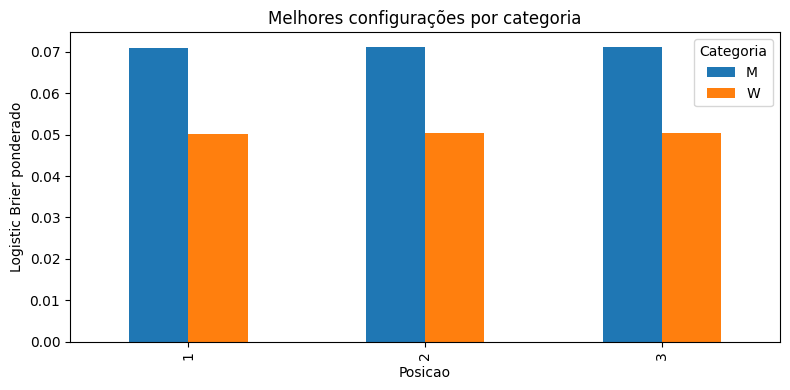

In [34]:
ranking_candidatos = ranquear_candidatos(avaliacao["scores"], REFERENCIAS_2026, ano_alvo=TEMPORADA_PREVISAO)
quantidades = ranking_candidatos.groupby("Categoria").size().reindex(CATEGORIAS, fill_value=0)
display(quantidades.rename("Candidatos com três validações completas").to_frame())
if quantidades.lt(TOP_N).any():
    raise RuntimeError("Menos de três candidatos completos em uma categoria. Corrija as falhas antes de gerar submissions.")
top3 = ranking_candidatos.loc[ranking_candidatos.Posicao.le(TOP_N)].merge(
    catalogo[["Categoria", "Candidato", "Parametros"]], on=["Categoria", "Candidato"], validate="one_to_one")
formula = " + ".join(f"{r.Peso:.8f} × LB_{int(r.Season)}" for r in REFERENCIAS_2026.itertuples())
print("Score(c, categoria) =", formula)
display(REFERENCIAS_2026)
display(top3.drop(columns="Parametros"))
for linha in top3.itertuples():
    print(f"{linha.Categoria} Top{linha.Posicao}: {linha.Candidato} ({linha.Familia})")
    display(linha.Parametros)
display(ranking_candidatos.groupby("Categoria").head(20))
ax = top3.pivot(index="Posicao", columns="Categoria", values="ScorePonderado").plot.bar(
    figsize=(8, 4), ylabel="Logistic Brier ponderado", title="Melhores configurações por categoria")
plt.tight_layout()
plt.show()


## Pares Top1 M/W, Top2 M/W e Top3 M/W

Os scores combinados abaixo reúnem as previsões externas dos candidatos já escolhidos.
Não usamos essa tabela para trocar os rankings por categoria. O ranking da posição 2/3
combinada pode diferir da ordem por categoria, pois o número de jogos M/W varia entre anos.


In [35]:
pares_scores = []
for posicao in range(1, TOP_N + 1):
    for referencia in REFERENCIAS_2026.itertuples():
        partes = []
        for categoria in CATEGORIAS:
            candidato_id = top3.loc[top3.Categoria.eq(categoria) & top3.Posicao.eq(posicao), "Candidato"].iloc[0]
            partes.append(avaliacao["previsoes"][(categoria, candidato_id, int(referencia.Season))])
        combinado = pd.concat(partes, ignore_index=True)
        pares_scores.append({"Posicao": posicao, "Season": int(referencia.Season), "Peso": referencia.Peso,
            "ScoreCombinado": logistic_brier(combinado.Target, combinado.Pred)})
pares_scores = pd.DataFrame(pares_scores)
pares_scores["Contribuicao"] = pares_scores.Peso * pares_scores.ScoreCombinado
display(pares_scores.pivot(index="Season", columns="Posicao", values="ScoreCombinado"))
display(pares_scores.groupby("Posicao").Contribuicao.sum().rename("Score ponderado combinado").to_frame())


Posicao,1,2,3
Season,,,
2023,0.076814,0.077323,0.076354
2024,0.058079,0.059015,0.059248
2025,0.050806,0.049914,0.050682


,Score ponderado combinado
Posicao,
1,0.060537
2,0.060670
3,0.060771


## Backtest opcional

`EXECUTAR_BACKTEST=True`, definido antes da avaliação, acrescenta os anos 2021/2022
às avaliações quando necessário (2.000 treinos principais em vez de 1.200).
Para cada alvo 2022–2025, escolhemos uma configuração por categoria usando apenas scores
anteriores ao alvo, comparamos similaridade ponderada e média passada uniforme.
Em 2022/2023 existem apenas uma/duas referências. Somente 2024/2025 têm três.

O banco de candidatos é independente de resultados, portanto pode ser reutilizado.
Se o vencedor escolhido no passado falhar no alvo, reportamos ausência em vez de
substituí-lo olhando o resultado externo. Esta análise não altera os Top 3 finais de 2026.


In [36]:
resultado_backtest = None
if EXECUTAR_BACKTEST:
    resultado_backtest = backtest_candidatos(perfis, avaliacao["scores"], anos=ANOS_BACKTEST, n_referencias=N_REFERENCIAS)
    display(resultado_backtest)
    display(resultado_backtest.groupby(["Categoria", "Estrategia"]).Score.agg(["mean", "count"]))
else:
    print("Backtest adicional não executado; seleção usa somente os três anos mais semelhantes.")


Backtest adicional não executado; seleção usa somente os três anos mais semelhantes.


## Confrontos 2026

Mesmos IDs, features pré-torneio e fallback dos experimentos anteriores.


In [37]:
sample_submission = dados["M"]["sample_submission"]
confrontos = preparar_confrontos(
    sample_submission, seeds["M"], seeds["W"],
    dados["M"]["times"]["TeamID"], dados["W"]["times"]["TeamID"],
    temporada=TEMPORADA_PREVISAO,
)
stats_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)]
    for stats in estatisticas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas(confrontos, stats_2026, permitir_ausentes=True)
detalhes_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)] for stats in detalhadas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas_detalhadas(confrontos, detalhes_2026, permitir_ausentes=True)
participantes = confrontos["TemDuasSeeds"]
assert (confrontos["TeamA"] < confrontos["TeamB"]).all()
assert np.isfinite(confrontos.loc[participantes, FEATURES].to_numpy()).all()
stats_index = stats_2026.set_index(["Season", "TeamID"])
for nome in ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]:
    pares = confrontos.loc[participantes]
    a = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[f"{nome}Diff"], a - b)

lookup = detalhes_2026.set_index(["Season", "TeamID"])
pares = confrontos.loc[participantes]
for nome in ESTATISTICAS_DETALHADAS:
    a = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[nome + "Diff"], a - b)


## Seis treinos finais e três submissions

Retreinamos somente as três configurações selecionadas de cada categoria, até 2025,
sem nova busca ou mudança de parâmetros. Top1 M + Top1 W gera o primeiro CSV, e assim
sucessivamente. Margens brutas, sem sigmoid ou clipping. As configurações e os scores
ponderados continuam sendo os da validação; RMSE CV final é apenas diagnóstico.

Os novos nomes terminam em `similarity_top1/2/3_2026.csv`. O CSV único da versão
anterior não é atualizado nem representa este novo protocolo.


In [38]:
execucoes_finais, modelos_finais, resumo_finais = {}, {}, []
arquivos_submission, resumo_submissions = {}, []
lookup_candidatos = {c["Candidato"]: c for banco in candidatos.values() for c in banco}
try:
    for linha in top3.itertuples(index=False):
        candidato = lookup_candidatos[linha.Candidato]
        assert candidato["Parametros"] == linha.Parametros
        treino = jogos[linha.Categoria].loc[jogos[linha.Categoria].Season < TEMPORADA_PREVISAO].copy()
        assert treino.Season.max() == 2025
        execucao = treinar_candidato_h2o(treino, candidato, features=FEATURES,
            ano_previsao=TEMPORADA_PREVISAO, n_folds=N_FOLDS_INTERNOS, seed=SEED)
        chave = (linha.Categoria, linha.Posicao)
        execucoes_finais[chave] = execucao
        modelos_finais[chave] = AdaptadorH2O(execucao["leader"], FEATURES)
        resumo_finais.append({"Categoria": linha.Categoria, "Posicao": linha.Posicao,
            "Candidato": linha.Candidato, "Familia": linha.Familia, "Parametros": candidato["Parametros"],
            "ScorePonderado": linha.ScorePonderado, "RMSE_CV_Final": execucao["rmse_cv"],
            "model_id": execucao["leader"].model_id})
    display(pd.DataFrame(resumo_finais).drop(columns="Parametros"))
    for posicao in range(1, TOP_N + 1):
        m, w = modelos_finais[("M", posicao)], modelos_finais[("W", posicao)]
        assert m.leader.model_id != w.leader.model_id
        previsoes = prever_confrontos(confrontos, m, w, features=FEATURES)
        assert previsoes.ID.equals(sample_submission.ID) and len(previsoes) == len(sample_submission)
        assert np.isfinite(previsoes.Pred).all()
        assert previsoes.loc[~participantes, "Pred"].eq(0).all()
        caminho = salvar_submission(previsoes, sample_submission,
            raiz / "submissions" / f"submission_exp10_h2o_similarity_top{posicao}_2026.csv")
        arquivos_submission[posicao] = caminho
        resumo_submissions.append({"Posicao": posicao, "Arquivo": caminho.name,
            "ModeloM": m.leader.model_id, "ModeloW": w.leader.model_id,
            "Linhas": len(previsoes), "MinPred": float(previsoes.Pred.min()), "MaxPred": float(previsoes.Pred.max())})
    display(pd.DataFrame(resumo_submissions))
finally:
    modelos_finais.clear()
    for execucao in execucoes_finais.values():
        limpar_execucao(execucao)


,Categoria,Posicao,Candidato,Familia,ScorePonderado,RMSE_CV_Final,model_id
0,M,1,M_XRT_793b1225e535,XRT,0.070948,11.725166,exp10_M_XRT_793b1225e535_2026_3c72b589
1,M,2,M_XRT_afa9ff32f122,XRT,0.071062,11.680885,exp10_M_XRT_afa9ff32f122_2026_4557c3f6
2,M,3,M_XRT_4c3423a096b9,XRT,0.071113,11.662725,exp10_M_XRT_4c3423a096b9_2026_52633e01
3,W,1,W_GBM_5eb2c4fb46fa,GBM,0.050126,12.971214,exp10_W_GBM_5eb2c4fb46fa_2026_26a44b46
4,W,2,W_GLM_5214eb6dc3e4,GLM,0.050278,12.328310,exp10_W_GLM_5214eb6dc3e4_2026_583855fb
5,W,3,W_GBM_3fc516d9a190,GBM,0.050429,12.979653,exp10_W_GBM_3fc516d9a190_2026_7b18f43b


,Posicao,Arquivo,ModeloM,ModeloW,Linhas,MinPred,MaxPred
0,1,submission_exp10_h2o_similarity_top1_2026.csv,exp10_M_XRT_793b1225e535_2026_3c72b589,exp10_W_GBM_5eb2c4fb46fa_2026_26a44b46,132133,-36.216005,47.208579
1,2,submission_exp10_h2o_similarity_top2_2026.csv,exp10_M_XRT_afa9ff32f122_2026_4557c3f6,exp10_W_GLM_5214eb6dc3e4_2026_583855fb,132133,-51.003731,57.489133
2,3,submission_exp10_h2o_similarity_top3_2026.csv,exp10_M_XRT_4c3423a096b9_2026_52633e01,exp10_W_GBM_3fc516d9a190_2026_7b18f43b,132133,-39.727636,49.824520


## Registro

Scores, espaços, falhas e configurações selecionadas ficam no notebook. Nenhuma pasta
results, binário de modelo ou novo ambiente virtual é criado. O ranking completo fica
em `ranking_candidatos`, e o catálogo reproduzível em `catalogo`.


In [39]:
registro = {
    "experimento": EXPERIMENTO, "features": FEATURES, "inicio_detalhado": INICIO_DETALHADO,
    "n_candidatos_por_categoria": N_CANDIDATOS, "espacos": ESPACOS, "seed": SEED,
    "n_folds_internos": N_FOLDS_INTERNOS, "n_threads": N_THREADS, "max_mem_size": MAX_MEM_SIZE,
    "anos_treinados": ANOS_TREINAR, "referencias_2026": REFERENCIAS_2026.to_dict("records"),
    "formula_score": formula, "regra_pesos": "inverso_da_distancia_normalizado",
    "metrica_principal": METRICA_PRINCIPAL, "ranking_similaridade": ranking_2026.to_dict("records"),
    "top3_por_categoria": top3.to_dict("records"), "modelos_finais": resumo_finais,
    "scores_candidatos": avaliacao["scores"].to_dict("records"), "falhas": avaliacao["falhas"].to_dict("records"),
    "backtest": None if resultado_backtest is None else resultado_backtest.to_dict("records"),
    "submissions": resumo_submissions,
    "versoes": {p: version(p) for p in ["h2o", "numpy", "pandas", "scipy", "scikit-learn"]},
}
display({k: registro[k] for k in ["n_candidatos_por_categoria", "anos_treinados", "formula_score", "versoes", "submissions"]})


{'n_candidatos_por_categoria': 200,
 'anos_treinados': [2023, 2024, 2025],
 'formula_score': '0.37467520 × LB_2025 + 0.34868020 × LB_2024 + 0.27664459 × LB_2023',
 'versoes': {'h2o': '3.46.0.12',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scipy': '1.15.3',
  'scikit-learn': '1.7.1'},
 'submissions': [{'Posicao': 1,
   'Arquivo': 'submission_exp10_h2o_similarity_top1_2026.csv',
   'ModeloM': 'exp10_M_XRT_793b1225e535_2026_3c72b589',
   'ModeloW': 'exp10_W_GBM_5eb2c4fb46fa_2026_26a44b46',
   'Linhas': 132133,
   'MinPred': -36.216005281938685,
   'MaxPred': 47.208578671284506},
  {'Posicao': 2,
   'Arquivo': 'submission_exp10_h2o_similarity_top2_2026.csv',
   'ModeloM': 'exp10_M_XRT_afa9ff32f122_2026_4557c3f6',
   'ModeloW': 'exp10_W_GLM_5214eb6dc3e4_2026_583855fb',
   'Linhas': 132133,
   'MinPred': -51.0037310999741,
   'MaxPred': 57.48913309056855},
  {'Posicao': 3,
   'Arquivo': 'submission_exp10_h2o_similarity_top3_2026.csv',
   'ModeloM': 'exp10_M_XRT_4c3423a096b9_2026_52633e01',


## Referência Kaggle — somente relatório

Os valores fornecidos pelo usuário não entram no banco, nas distâncias ou na seleção.

| Submissão | Score Kaggle 2026 |
|---|---:|
| Exp. 8 — Top1 | 0.04816 |
| Exp. 8 — Top2 | 0.04783 |
| Exp. 8 — Top3 | 0.04874 |
| Exp. 10 — candidatos Top1 | 0.05335 |
| Exp. 10 — candidatos Top2 | 0.05038 |
| Exp. 10 — candidatos Top3 | 0.05479 |

Resultados informados pelo usuário no [Kaggle](https://www.kaggle.com/competitions/march-machine-learning-mania-2026-logistic-brier/submissions), com status Complete (after deadline).
Arquivos: `submission_exp10_h2o_similarity_top1_2026.csv`, `submission_exp10_h2o_similarity_top2_2026.csv` e `submission_exp10_h2o_similarity_top3_2026.csv`.
O Top2 teve o menor score do Exp. 10 (0.05038), mas ficou acima do melhor resultado registrado do Exp. 8 (0.04783). Menor é melhor.

Os scores ponderados de seleção usam anos/pesos diferentes da média 2021–2025 do Exp. 8;
não devem ser tratados como a mesma avaliação. Os CSVs Top1/2/3 são definidos antes do Kaggle.
